# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |

## Modelo del sistema

*TODO(b-Tomas): diagrama de bloques*

In [79]:
# Todos los imports van acá
import matplotlib.pyplot as plt
import numpy as np
from math import sqrt

## Transmisión

El módulo transmisor se compone de dos partes: el codificador y el conformador de onda.

### Codificador

Se considera como objetivo transmitir y recibir un conjunto de bits. Para esto, se debe convertir el conjunto de bits en símbolos.

El bloque de parámetros ya define los símbolos a enviar en la lista `symbols`, por lo que primero se retrocederá un paso para convetirlos en el conjunto de bits a enviar. Luego, `encoder()` tomará el conjunto de bits y los convertirá en símbolos.

Cada símbolo se genera con un vector $w(nT_s)$ de $SF$ bits de acuerdo a Ec. 1:

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

$w_0$ es el bit menos significativo. El flujo de bits se corta en grupos de $SF$ bits, un grupo por símbolo.

In [80]:
def encoder(bits: np.ndarray, SF: int) -> np.ndarray:
    """Convierte un conjunto de bits en símbolos.

    Organiza `bits` en grupos $w(nT_s)$ de `SF` bits y los convierte a símbolos.

    Args:
        bits (np.ndarray): Conjunto de bits a transmitir.
        SF (int): Spreading factor.

    Returns:
        np.ndarray: Conjunto de símbolos a transmitir.
    """

    # Validar la forma del vector de bits a enviar
    assert bits.size % SF == 0, "El número de bits debe ser múltiplo de SF"

    # Reorganizar los bits en grupos de SF bits
    # El resultado es un arreglo de forma (N, SF) donde N es el número de símbolos.
    # Cada símbolo es un vector equivalente a $w(nT_s)$
    W = bits.reshape(-1, SF)

    # Secuencia h = 0..SF-1
    h = np.arange(SF)

    # Convertir cada grupo de SF bits a un símbolo
    # 2**h produce un vector de potencias de 2: [1, 2, 4, ..., 2**(SF-1)]
    # W @ 2**h realiza el producto matricial, sumando los productos de cada bit por su correspondiente potencia de 2.
    return W @ 2**h

In [81]:
# Tests
assert np.array_equal(encoder(np.array([0, 0, 0, 1, 0, 0, 0]), 7), np.array([8]))
assert np.array_equal(
    encoder(np.array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]), 7), np.array([8, 127])
)

### Conformador de onda

Dado el vector de símbolos $s(nT_s)$, el conformador de onda genera la señal modulada de acuerdo a Ec. 2 para cada símbolo $n$ y cada chip $k = 0, \dots, 2^{SF}-1$:

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

In [82]:
def modulator(symbols: np.ndarray, SF: int, B: float) -> np.ndarray:
    """Genera la forma de onda FSCM para una secuencia de símbolos.

    Muestrea a k = 0..2**SF-1 chips por cada símbolo n.

    Args:
        symbols (np.ndarray): Conjunto de símbolos $s(nT_s)$ a transmitir. 0 <= s < 2**SF.
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.

    Returns:
        np.ndarray: Señal modulada (compleja) en el dominio del tiempo.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Tiempo de chip
    T = 1 / B

    # Convertir s a un vector de forma (N, 1) para poder sumarle k
    s = symbols.reshape(-1, 1)  # Vector columna de símbolos

    # Vector de chips k = 0..M-1
    k = np.arange(M)  # Vector fila de chips

    # Frecuencia instantanea de la señal modulada: f(k) = (s + k) mod M * B / M
    # Es el exponente en la Ec. 2, sin el muestreo kT
    f = ((s + k) % M) * B / M

    # c[n, k] = c(nT_s + kT). Vector de forma (N, M) donde N es el número de símbolos y M es el número de chips por símbolo.
    c = np.exp(1j * 2 * np.pi * f * k * T) / np.sqrt(M)

    return c.ravel()  # Aplanar a un vector unidimensional de chips

#### Análisis de la señal modulada

Antes de continuar con la transmisión, se analiza la forma y comportamiento de la señal modulada en tiempo y en frecuencia en una configuración con *Spreading Factor* de 7.

In [83]:
SF = 7
symbols = np.array([0, 32, 80])
B = 125e3  # Ancho de banda de 125 kHz

c = modulator(symbols, SF, B)

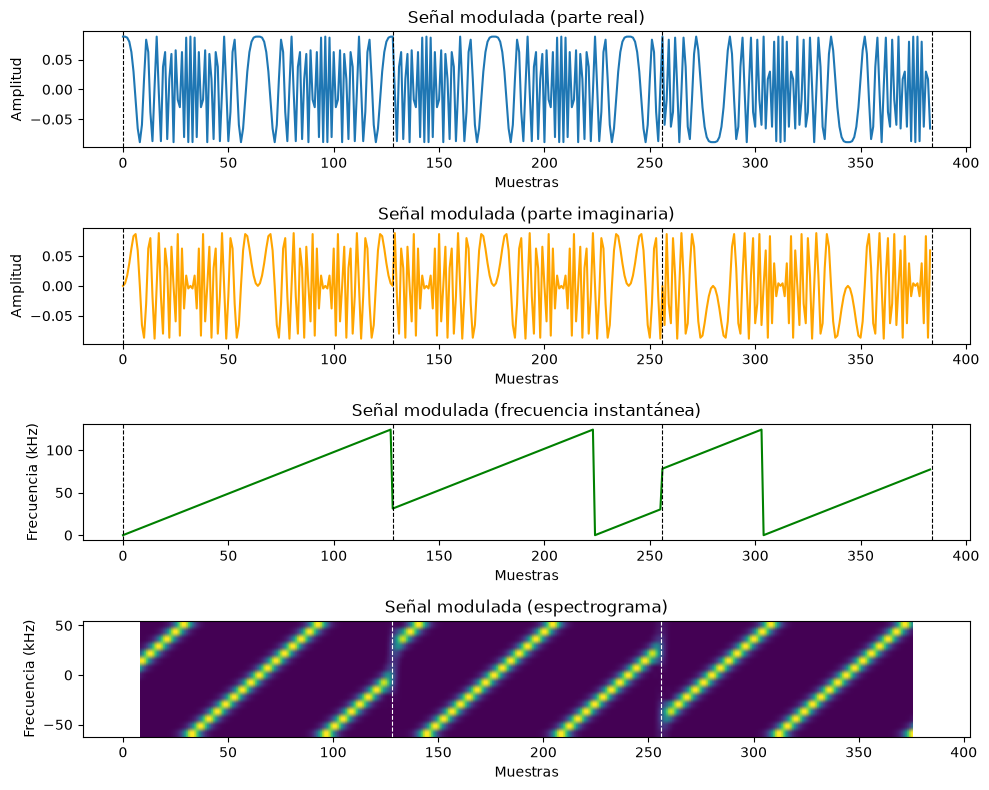

In [84]:
# Señal real e imaginaria de la señal modulada en el tiempo
plt.figure(figsize=(10, 8))
plt.subplot(4, 1, 1)
plt.plot(np.real(c), label="Real")
plt.title("Señal modulada (parte real)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.subplot(4, 1, 2)
plt.plot(np.imag(c), label="Imag", color="orange")
plt.title("Señal modulada (parte imaginaria)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
# Frecuencia instantánea en el tiempo: f(k) = (s + k) mod M * B / M
plt.subplot(4, 1, 3)
k = np.arange(2**SF)
f = ((symbols.reshape(-1, 1) + k) % 2**SF) * B / 2**SF
plt.plot(f.ravel() / 1e3, color="green")
plt.title("Señal modulada (frecuencia instantánea)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
# Espectrograma: frecuencia en el tiempo estimada a partir de la señal c
plt.subplot(4, 1, 4)
N = 16  # muestras por ventana de la FFT
# xextent: eje x en muestras, como los otros gráficos (cada ventana se ubica en su centro)
plt.specgram(
    c,
    NFFT=N,
    noverlap=N - 1,
    Fs=B / 1e3,
    sides="twosided",
    scale="linear",
    xextent=(N / 2, c.size - N / 2),
)
plt.title("Señal modulada (espectrograma)")
plt.xlabel("Muestras")
plt.ylabel("Frecuencia (kHz)")
# Separación entre símbolos: un símbolo (Ts) son 2**SF muestras
for ax in plt.gcf().axes:
    for n in range(len(symbols) + 1):
        # Blanco sobre el espectrograma (fondo oscuro), negro en el resto
        ax.axvline(n * 2**SF, color="w" if ax.images else "k", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

**Dominio del tiempo**:
- La señal es una exponencial compleja de frecuencia variable, conocida como *chirp*.
- La parte real es una onda cosenoidal de frecuencia creciente, mientras que la parte imaginaria es una onda senoide de frecuencia creciente.

**Frecuencia instantánea**:
- El gráfico muestra la frecuencia instantánea de la señal de la Ec. 2. con fines pedagógicos.
- De acuerdo con lo que se puede ver en las ondas de la parte real e imaginaria, la frecuencia instantánea es una función lineal del tiempo, que aumenta de 0 a $B$ en el intervalo de tiempo $T_s$.
- La frecuencia instantánea inicial para cada símbolo es distinta de acuerdo a $f_0 = \frac{B}{2^{SF}} s(nT_s)$.

**Espectrograma:**
- Muestra la frecuencia real de $c$.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas, y genera símbolos a partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

Se analizará primero demodulando la señal modulada, y luego sumándole ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

El proceso de demodulación de forma computacionalmente eficiente se describe en Ec. 16 como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{q}$:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

Se puede interpretar como la correlación entre la señal recibida y todos los *chirps* posibles, siendo el *chirp* que maximiza la proyección el símbolo recibido.

El término $e^{-j2\pi \frac{k^2}{2^{SF}}}$ se conoce como *down-chirp*. El resultado $d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j2\pi \frac{k^2}{2^{SF}}}$ es una exponencial compleja de frecuencia constante igual a la frecuencia inicial del símbolo recibido. Se utiliza la transformada rápida de Fourier (FFT).

Luego, la transformada de Fourier de $d(nT_s + kT)$ resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.


In [85]:
def demodulator(r: np.ndarray, SF: int) -> np.ndarray:
    """Demodula una señal LoRa de Spreading-Factor SF según Ec. 16.

    Args:
        r: Señal LoRa modulada recibida.
        SF: Spreading-Factor.

    Returns:
        np.ndarray: Arreglo unidimensional de símbolos demodulados.
    """

    # Chips por símbolo
    M: int = 2**SF

    # Validar el largo del array
    assert r.size % M == 0, "El número de chirps debe ser múltiplo de SF"

    # Convertir s a un vector de forma (N, M): R[n, k] = r(nT_s + kT)
    R = r.reshape(-1, M)  # Vector columna de símbolos

    # Vector de chips k = 0..M-1
    k = np.arange(M)  # Vector fila de chips

    # Obtener d(nT_s + kT) = r(nT_s + kT) * downchirp
    downchirp = np.exp(-1j * 2 * np.pi * k**2 / M)
    d = R * downchirp

    # Transformada de Fourier (discreta) de cada fila (símbolo)
    # norm="ortho" normaliza la FFT para que la salida sea unitiaria (conserve la energía de la señal)
    # equivalente a aplicar el factor 1/sqrt(M) de Ec. 16 a la salida de la FFT
    D = np.fft.fft(d, norm="ortho")

    # Decidir el símbolo demodulado como el índice del máximo de la FFT
    return np.argmax(np.abs(D) ** 2, axis=1)

In [86]:
# Tests
assert np.array_equal(demodulator(modulator(symbols, SF, B), SF), symbols)

#### Visualización del proceso de decisión

Para cada símbolo recibido se obtiene la frecuencia inicial del *chirp* recibido mediante el *down-chirp* y la FFT. La transformada de Fourier de $d(nT_s + kT)$ (una exponencial compleja de frecuencia constante) resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.

Mas adelante se analizará la decisión en un canal ruidoso.

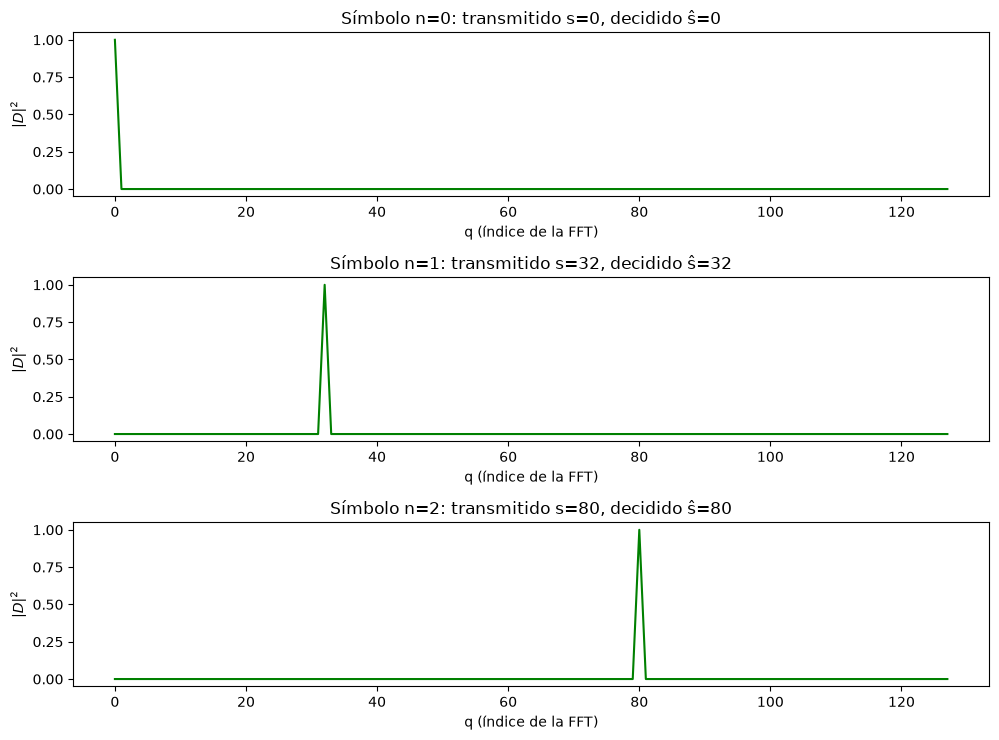

In [87]:
# Repetir los pasos de demodulator para ver la salida de la FFT antes de decidir
M: int = 2**SF
k = np.arange(M)
# Multiplicar cada símbolo recibido por el down-chirp
d = c.reshape(-1, M) * np.exp(-1j * 2 * np.pi * k**2 / M)
# FFT de cada símbolo
D = np.fft.fft(d, norm="ortho")
# Decisión: índice del máximo de |D|^2
symbols_rx = demodulator(c, SF)

plt.figure(figsize=(10, 2.5 * len(symbols)))
for n in range(len(symbols)):
    plt.subplot(len(symbols), 1, n + 1)
    plt.plot(np.abs(D[n]) ** 2, color="green")
    plt.title(f"Símbolo n={n}: transmitido s={symbols[n]}, decidido ŝ={symbols_rx[n]}")
    plt.xlabel("q (índice de la FFT)")
    plt.ylabel("$|D|^2$")
plt.tight_layout()
plt.show()

### Decodificación

Se descompone cada símbolo en un arreglo de $SF$ bits de acuerdo a Ec. 1.

In [88]:
def decoder(symbols: np.ndarray, SF: int) -> np.ndarray:
    """Convierte un conjunto de símbolos en bits.

    Descompone cada símbolo en un arreglo de `SF` bits de acuerdo a Ec. 1.

    Args:
        symbols (np.ndarray): Conjunto de símbolos a decodificar.
        SF (int): Spreading factor.

    Returns:
        np.ndarray: Conjunto de bits decodificados.
    """

    # Convertir los símbolos a un arreglo columna de forma (N, 1) para poder resolver como
    # una operación matricial
    s = symbols.reshape(-1, 1)  # Vector columna de símbolos

    # Secuencia h = 0..SF-1
    h = np.arange(SF)

    # Expande cada vector de un símbolo a un arreglo de SF bits
    # Se desplaza el símbolo h veces a la derecha para cada valor de h, para cada símbolo
    # Nos quedamos con el bit menos significativo
    W = (s >> h) & 1

    # Aplanar a un vector unidimensional de bits
    return W.ravel()

In [89]:
# Tests
assert np.array_equal(decoder(np.array([8]), 7), np.array([0, 0, 0, 1, 0, 0, 0]))
assert np.array_equal(
    decoder(np.array([8, 127]), 7), np.array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1])
)

## Cálculo del Bit Error Rate (BER)

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

Ya que aún no hemos introducido ruido en el canal, esperamos que el BER sea 0.

In [90]:
def BER(bits_tx: np.ndarray, bits_rx: np.ndarray) -> float:
    """Calcula el Bit Error Rate (BER) comparando los bits transmitidos y recibidos.

    Args:
        bits_tx (np.ndarray): Conjunto de bits transmitidos.
        bits_rx (np.ndarray): Conjunto de bits recibidos.

    Returns:
        float: Bit Error Rate (BER).
    """

    # Validar que ambos conjuntos de bits tengan la misma longitud
    assert bits_tx.size == bits_rx.size, "Los conjuntos de bits deben tener la misma longitud"

    # Obtener los bits erróneos con un XOR entre los bits transmitidos y recibidos
    return sum(bits_tx ^ bits_rx) / bits_tx.size

In [91]:
# Simular una transmisión completa
SF = 7
B = 125e3
# Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
bits_tx = np.random.randint(0, 2, size=SF * 100)
bits_rx = decoder(demodulator(modulator(encoder(bits_tx, SF), SF, B), SF), SF)  # Bits recibidos
ber = BER(bits_tx, bits_rx)  # Calcular el BER
print(f"Bit Error Rate (BER): {ber:.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


## Potencia de la señal modulada

In [92]:
def power(c: np.ndarray) -> float:
    """Calcula la potencia de la señal modulada.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.

    Returns:
        float: Potencia de la señal modulada.
    """

    # La potencia de una señal compleja es el valor medio de su magnitud al cuadrado
    return np.mean(np.abs(c) ** 2)

In [93]:
# Simular una transmisión completa
SF = 7
B = 125e3
# Conjunto de 100 símbolos aleatorios
symbols_tx = np.random.randint(0, 2**SF, size=100)
print(
    f"Potencia de la señal modulada con SF={SF}, B={B}kHz: {power(modulator(np.array([0]), SF, B)):.4f}"
)

SF = 2  # type: ignore
print(
    f"Potencia de la señal modulada con SF={SF}, B={B}kHz: {power(modulator(np.array([0]), SF, B)):.4f}"
)

Potencia de la señal modulada con SF=7, B=125000.0kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125000.0kHz: 0.2500


## Modelo de canal ruidoso

El canal dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y desplazamiento. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

In [94]:
def noise_from_SNR(c: np.ndarray, SNR_dB: float) -> np.ndarray:
    """Genera ruido blanco gaussiano aditivo (AWGN) a partir de la señal modulada y la relación señal-ruido (SNR) que se quiera simular.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.
        SNR_dB (float): Relación señal-ruido en decibelios.

    Returns:
        np.ndarray: Señal con ruido aditivo.
    """
    # Convertir SNR de dB a lineal
    SNR_linear = 10 ** (SNR_dB / 10)

    # Calcular la potencia de la señal
    signal_power = power(c)

    # Calcular la potencia del ruido: SNR = signal_power / noise_power => noise_power = signal_power / SNR
    z_power = signal_power / SNR_linear

    # La potencia del ruido gaussiano es igual a la varianza de la distribución normal
    # Se divide la potencia a partes iguales entre la parte real e imaginaria del ruido complejo
    # La desviación estándar es la raíz cuadrada de la varianza
    component_sigma = np.sqrt(z_power / 2)

    # Generar ruido blanco gaussiano.
    # Tiene que ser una exponencial compleja, por lo que se genera ruido para la parte real e imaginaria.
    z = np.random.normal(0, component_sigma, c.shape) + 1j * np.random.normal(
        0, component_sigma, c.shape
    )

    return z

In [95]:
def system(c: np.ndarray, h: np.ndarray, z: np.ndarray) -> np.ndarray:
    """Simula la transmisión de la señal modulada a través de un canal ruidoso.

    Args:
        c (np.ndarray): Señal modulada (compleja) en el dominio del tiempo.
        h (np.ndarray): Respuesta al impulso del canal.
        z (np.ndarray): Ruido blanco gaussiano aditivo (AWGN).

    Returns:
        np.ndarray: Señal recibida después de pasar por el canal ruidoso.
    """
    # Convolución de la señal modulada con la respuesta al impulso del canal
    # mode="same" asegura que la salida tenga el mismo tamaño que la señal de entrada
    c_channel = np.convolve(c, h, mode="same")

    # Sumar el ruido a la señal distorsionada por el canal
    return c_channel + z

In [96]:
def simulation(SF: int, B: float, SNR_dB: float, h: np.ndarray, num_symbols: int = 100) -> float:
    """Simula la transmisión de una señal LoRa a través de un canal ruidoso y calcula el BER.

    Args:
        SF (int): Spreading factor.
        B (float): Ancho de banda de la señal.
        SNR_dB (float): Relación señal-ruido en decibelios.
        h (np.ndarray): Respuesta al impulso del canal.

    Returns:
        float: Bit Error Rate (BER) de la transmisión simulada.
    """
    # Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
    bits_tx = np.random.randint(0, 2, size=SF * num_symbols)

    # Transmisión completa
    c = modulator(encoder(bits_tx, SF), SF, B)  # Señal modulada
    z = noise_from_SNR(c, SNR_dB)  # Ruido generado a partir de la señal y el SNR
    r = system(c, h, z)  # Señal recibida después del canal ruidoso

    # Demodulación y decodificación
    bits_rx = decoder(demodulator(r, SF), SF)

    # Calcular el BER
    return BER(bits_tx, bits_rx)

In [97]:
# Parámetros de la simulación
SF = 7
B = 125e3
h_flat = np.array([1.0])  # Respuesta al impulso neutra
SNR_dB = -10

# Conjunto de bits aleatorios a transmitir correspondiente a 100 símbolos
bits_tx = np.random.randint(0, 2, size=SF * 100)

# Simular una transmisión completa
ber = simulation(SF, B, SNR_dB, h_flat)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0100


### Detección con ruido en un canal plano

Se repite la simulación de la transmisión y recepción de símbolos, pero esta vez se introduce ruido blanco gaussiano aditivo (AWGN) en el canal.

El canal es plano, es decir, respuesta en frecuencia constante.

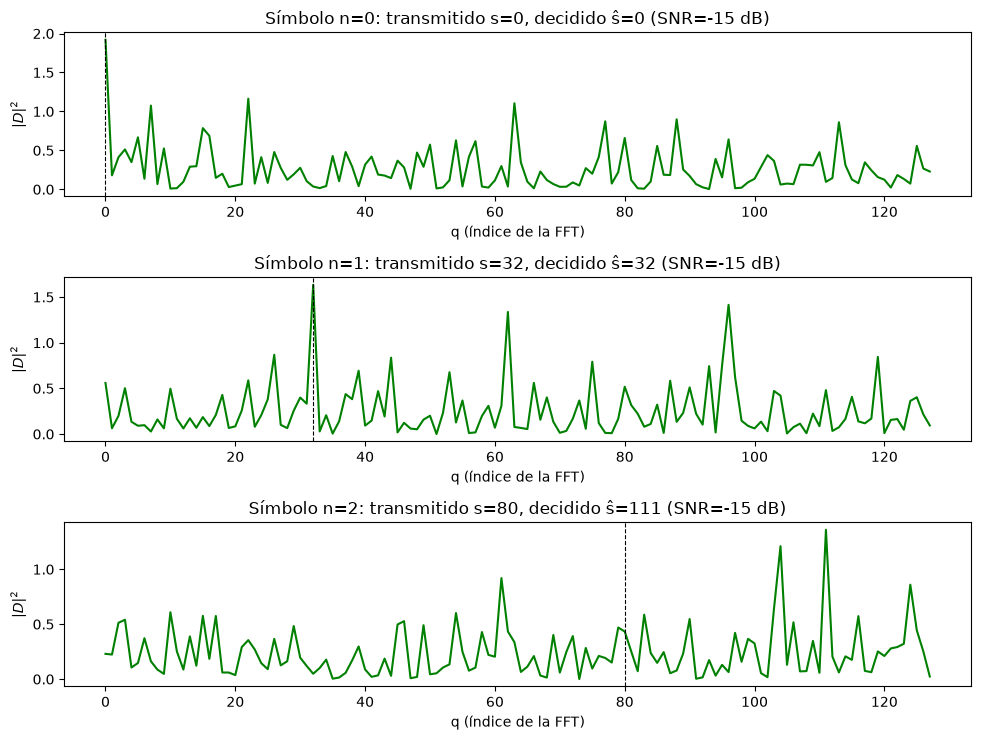

In [98]:
# Parámetros: probar distintos SNR para ver cuándo empieza a fallar la decisión
SF = 7
B = 125e3
symbols = np.array([0, 32, 80])
h_flat = np.array([1.0])  # Respuesta al impulso neutra
SNR_dB = -15

# Transmisión a través del canal ruidoso
c = modulator(symbols, SF, B)
z = noise_from_SNR(c, SNR_dB)
r = system(c, h_flat, z)

# Repetir los pasos de demodulator para ver la salida de la FFT antes de decidir
M: int = 2**SF
k = np.arange(M)
# Multiplicar cada símbolo recibido por el down-chirp
d = r.reshape(-1, M) * np.exp(-1j * 2 * np.pi * k**2 / M)
# FFT de cada símbolo
D = np.fft.fft(d, norm="ortho")
# Decisión: índice del máximo de |D|^2
symbols_rx = demodulator(r, SF)

plt.figure(figsize=(10, 2.5 * len(symbols)))
for n in range(len(symbols)):
    plt.subplot(len(symbols), 1, n + 1)
    plt.plot(np.abs(D[n]) ** 2, color="green")
    # Símbolo transmitido, para comparar con el pico
    plt.axvline(symbols[n], color="k", ls="--", lw=0.8)
    plt.title(
        f"Símbolo n={n}: transmitido s={symbols[n]}, decidido ŝ={symbols_rx[n]} (SNR={SNR_dB} dB)"
    )
    plt.xlabel("q (índice de la FFT)")
    plt.ylabel("$|D|^2$")
plt.tight_layout()
plt.show()

### Detección con ruido en un canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia. La respuesta al impulso del sistema usado para modelar un canal multicaminos es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$



### Performance de detección

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

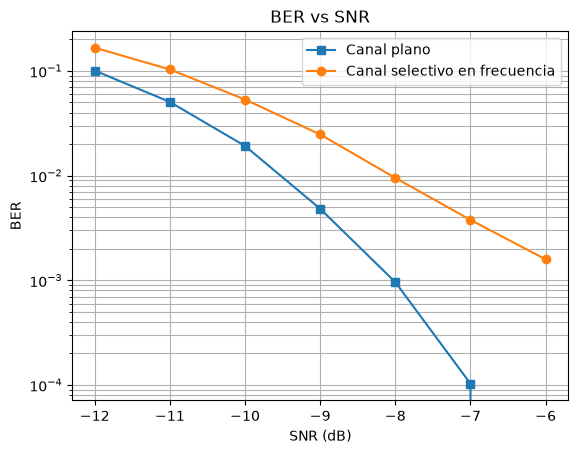

In [99]:
SF = 7
B = 125e3
h_flat = np.array([1.0])  # Canal plano (solo AWGN)
h_freq_sel = np.array([sqrt(0.8), sqrt(0.2)])
SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -5 dB
num_symbols = 100  # Número de símbolos por simulación
simulations = 500  # Cantidad de simulaciones

# 300 simulaciones de 700 bits por punto con canal plano
bers_flat = [
    np.mean([simulation(SF, B, SNR_dB, h_flat) for _ in range(simulations)]) for SNR_dB in SNRs_dB
]
# 300 simulaciones de 700 bits por punto con canal selectivo en frecuencia
bers_freq_sel = [
    np.mean([simulation(SF, B, SNR_dB, h_freq_sel) for _ in range(simulations)])
    for SNR_dB in SNRs_dB
]

plt.semilogy(SNRs_dB, bers_flat, marker="s", label="Canal plano")
plt.semilogy(SNRs_dB, bers_freq_sel, marker="o", label="Canal selectivo en frecuencia")
plt.title("BER vs SNR")
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.grid(True, which="both")
plt.legend()
plt.show()